In [ ]:
!pip install segmentation-models-pytorch==0.4.0

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.3/121.3 kB 8.0 MB/s eta 0:00:00
  Created wheel for efficientnet-pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16426 sha256=46ebed96e59e3f9c99a394d06c3b0272beab9a73f8871e82fbe5bcb5b800f54a
  Stored in directory: /root/.cache/pip/wheels/9c/3f/43/e6271c7026fe08c185da2be23c98c8e87477d3db63f41f32ad
  Created wheel for pretrainedmodels: filename=pretrainedmodels-0.7.4-py3-none-any.whl size=60945 sha256=b91857558c2f30c87a0e1e5d37dc8c8469843a54d9f748b948275741b6734a42
  Stored in directory: /root/.cache/pip/wheels/4c/01/56/40a48f75dbdfe167a0cb70d3b48913369a00ec5c4e9fed5f2b
Successfully built efficientnet-pytorch pretrainedmodels


In [ ]:
!pip install albumentations==1.3.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 8.3 MB/s eta 0:00:00
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8


In [ ]:
!pip install opencv-python==4.8.1.78

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 MB 15.9 MB/s eta 0:00:00
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.13.0.92
    Uninstalling opencv-python-4.13.0.92:
      Successfully uninstalled opencv-python-4.13.0.92


In [ ]:
!pip install numpy==1.26.4

In [ ]:
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

import os
import glob
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device: ", device)

Using device:  cuda


In [ ]:
def dice_coef(pred, target, eps=1e-7):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    intersection = (pred * target).sum(dim=(1,2,3))
    union = pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean()


def iou_score(preds, targets, threshold=0.5, eps=1e-6):
    preds = torch.sigmoid(preds)
    preds = (preds > threshold).float()

    intersection = (preds * targets).sum(dim=(2, 3))
    union = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3)) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean()

In [ ]:
from pathlib import Path
from PIL import Image

class AortaDataset(torch.utils.data.Dataset):
    def __init__(self, transform, root="data"):
        self.root = Path(root)
        self.transform = transform

        self.img_filenames = sorted(glob.glob(root + "/images/*.png"))
        if len(self.img_filenames) == 0:
            self.img_filenames = sorted(glob.glob(root + "/images/*.jpg"))
        self.mask_filenames = sorted(glob.glob(root + "/masks/*.png"))
        if len(self.mask_filenames) == 0:
            self.mask_filenames = sorted(glob.glob(root + "/masks/*.jpg"))


    def __getitem__(self, idx):
        image = np.asarray(
            Image.open(self.img_filenames[idx]).convert("L"),
            dtype=np.float32
        ) / 255.0

        mask = np.asarray(
            Image.open(self.mask_filenames[idx]).convert("L"),
            dtype=np.uint8
        )

        transformed = self.transform(image=image, mask=mask)

        image = transformed["image"]
        mask = transformed["mask"]


        image = image.repeat(3, 1, 1)


        mask = (mask > 0).float()
        mask = mask.unsqueeze(0)


        return image, mask

    def __len__(self):
        return len(self.img_filenames)


train_transform = A.Compose([
    A.Resize(height=512, width=512),
    A.Rotate(limit=(-30, 30), p=0.9),
    A.RandomBrightnessContrast(p=0.7),
    A.ElasticTransform(alpha=70, sigma=10, p=0.5),
    A.GridDistortion(p=0.5),
    A.OpticalDistortion(p=0.5),
    A.GaussianBlur(p=0.3),
    A.CoarseDropout(max_holes=8, max_height=64, max_width=64, p=0.3),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(height=512, width=512),
    ToTensorV2()
])


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

extract_path = "/content/drive/MyDrive/aorta589/dataset"

all_files = os.listdir(extract_path)
img_path = sorted([os.path.join(extract_path, f) for f in all_files if f.endswith(".jpg")])
mask_path = sorted([os.path.join(extract_path, f) for f in all_files if f.endswith(".png") or "AO" in f])

print("Found images: ", len(img_path))
print("Found masks: ", len(mask_path))

Found images:  589
Found masks:  589


In [ ]:
from sklearn.model_selection import train_test_split


train_img, val_img, train_mask, val_mask = train_test_split(
    img_path, mask_path,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print(f"Train: {len(train_img)} изображений")
print(f"Val:   {len(val_img)} изображений")


train_dataset = AortaDataset(train_transform, root="")
train_dataset.img_filenames = train_img
train_dataset.mask_filenames = train_mask

val_dataset = AortaDataset(val_transform, root="")
val_dataset.img_filenames = val_img
val_dataset.mask_filenames = val_mask

Train: 471 изображений
Val:   118 изображений


In [ ]:
from torch.utils.data import DataLoader

batch_size = 4

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.reset_accumulated_memory_stats()


train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")

Train batches: 118
Val batches:   30


In [ ]:
model = smp.DeepLabV3Plus(
    encoder_name="tu-convnext_femto",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None,
)

model = model.to(device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/20.9M [00:00<?, ?B/s]

In [ ]:
from segmentation_models_pytorch.losses import DiceLoss

criterion = DiceLoss(mode="binary", from_logits=True, smooth=1e-6)
bce = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=1e-6)

In [ ]:
from tqdm import tqdm

def train_epoch(model, loader, optimizer, scheduler=None):
    model.train()
    total_loss = 0
    total_dice = 0
    total_iou = 0

    pbar = tqdm(loader, desc="Обучение")
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks) + 0.5 * bce(outputs, masks)
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            dice = dice_coef(outputs, masks)
            iou = iou_score(outputs, masks)

        total_loss += loss.item()
        total_dice += dice.item()
        total_iou += iou.item()

        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'dice': f'{dice.item():.4f}',
            'iou': f'{iou.item():.4f}'
        })

    if scheduler:
        scheduler.step()

    return total_loss/len(loader), total_dice/len(loader), total_iou/len(loader)

@torch.no_grad()
def validate_epoch(model, loader):
    model.eval()
    total_loss = 0
    total_dice = 0
    total_iou = 0

    pbar = tqdm(loader, desc="Валидация")
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        loss = criterion(outputs, masks) + 0.5 * bce(outputs, masks)
        dice = dice_coef(outputs, masks)
        iou = iou_score(outputs, masks)

        total_loss += loss.item()
        total_dice += dice.item()
        total_iou += iou.item()

        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'dice': f'{dice.item():.4f}',
            'iou': f'{iou.item():.4f}'
        })

    return total_loss/len(loader), total_dice/len(loader), total_iou/len(loader)

In [ ]:
num_epochs = 200
best_dice = 0
best_epoch = 0

history = {
    'train_loss': [], 'val_loss': [],
    'train_dice': [], 'val_dice': [],
    'train_iou': [], 'val_iou': []
}

print("\n" + "="*60)
print("ОБУЧЕНИЕ CONVNEXT НА АОРТЕ")
print("="*60)
print(f"-- Всего данных: {len(img_path)} изображений")
print(f"--Train: {len(train_img)}, Val: {len(val_img)}")
print(f"-- Размер: 512x512")
print(f"-- Батч: {batch_size}")
print(f"-- Эпох: {num_epochs}")
print("="*60 + "\n")

for epoch in range(num_epochs):
    print(f"\n-- Эпоха {epoch + 1}/{num_epochs}")
    print("-"*40)

    train_loss, train_dice, train_iou = train_epoch(model, train_loader, optimizer, scheduler)
    val_loss, val_dice, val_iou = validate_epoch(model, val_loader)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_dice'].append(train_dice)
    history['val_dice'].append(val_dice)
    history['train_iou'].append(train_iou)
    history['val_iou'].append(val_iou)

    print(f"\n РЕЗУЛЬТАТЫ:")
    print(f"   Train - Loss: {train_loss:.4f}, Dice: {train_dice:.4f}, IoU: {train_iou:.4f}")
    print(f"   Val   - Loss: {val_loss:.4f}, Dice: {val_dice:.4f}, IoU: {val_iou:.4f}")
    print(f"   LR: {optimizer.param_groups[0]['lr']:.2e}")

    if val_dice > best_dice:
        best_dice = val_dice
        best_epoch = epoch + 1

        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_dice': val_dice,
            'val_iou': val_iou,
            'history': history
        }, '/content/drive/MyDrive/best_convnext_deeplab2.pth')

        print(f"\n✅ НОВАЯ ЛУЧШАЯ МОДЕЛЬ! Dice: {best_dice:.4f} IOU: {val_iou:.4f}")

    if epoch - best_epoch > 15:
        print(f"\n Ранняя остановка")
        break

print("\n" + "="*60)
print(" ОБУЧЕНИЕ ЗАВЕРШЕНО!")
print(f"   Лучший Dice (валидационная выборка): {best_dice:.4f} на эпохе {best_epoch}")
print(f"   Модель сохранена: /content/drive/MyDrive/best_convnext_deeplab2.pth")
print("="*60)

max_train_epoch = np.argmax(history["train_dice"])

train_dice = history["train_dice"][max_train_epoch]
train_iou = history['train_iou'][max_train_epoch]

print(f"   Лучший Dice (тренировочная выборка): {train_dice:.4f} на эпохе {max_train_epoch + 1} IOU: {train_iou:.4f}")


ОБУЧЕНИЕ CONVNEXT НА АОРТЕ
-- Всего данных: 589 изображений
--Train: 471, Val: 118
-- Размер: 512x512
-- Батч: 4
-- Эпох: 200


-- Эпоха 1/200
----------------------------------------


Обучение:   3%|▎         | 4/118 [00:15<04:17,  2.26s/it, loss=1.3188, dice=0.0175, iou=0.0089]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(mask)
Обучение:   7%|▋         | 8/118 [00:29<05:07,  2.80s/it, loss=1.3181, dice=0.0202, iou=0.0102]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy th


 РЕЗУЛЬТАТЫ:
   Train - Loss: 1.2197, Dice: 0.0849, IoU: 0.0612
   Val   - Loss: 1.1764, Dice: 0.1475, IoU: 0.1059
   LR: 9.99e-06

✅ НОВАЯ ЛУЧШАЯ МОДЕЛЬ! Dice: 0.1475 IOU: 0.1059

-- Эпоха 2/200
----------------------------------------


Обучение:  57%|█████▋    | 67/118 [00:24<00:20,  2.46it/s, loss=1.2772, dice=0.0771, iou=0.0409]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(mask)
Обучение:  78%|███████▊  | 92/118 [00:33<00:06,  4.05it/s, loss=1.2643, dice=0.1094, iou=0.0593]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy 


 РЕЗУЛЬТАТЫ:
   Train - Loss: 1.1749, Dice: 0.1414, IoU: 0.1008
   Val   - Loss: 1.1308, Dice: 0.1601, IoU: 0.1131
   LR: 9.96e-06

✅ НОВАЯ ЛУЧШАЯ МОДЕЛЬ! Dice: 0.1601 IOU: 0.1131

-- Эпоха 3/200
----------------------------------------


Обучение:  12%|█▏        | 14/118 [00:05<00:36,  2.86it/s, loss=0.6851, dice=0.4156, iou=0.3473]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(mask)
Обучение:  50%|█████     | 59/118 [00:25<00:32,  1.84it/s, loss=1.2298, dice=0.1282, iou=0.0691]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy 

... (391 outputs left out)

Обучение:   3%|▎         | 4/118 [00:02<01:05,  1.74it/s, loss=0.0196, dice=0.9143, iou=0.8473]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(mask)
Обучение:  44%|████▍     | 52/118 [00:23<00:28,  2.32it/s, loss=0.1313, dice=0.8926, iou=0.8097]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy t


 РЕЗУЛЬТАТЫ:
   Train - Loss: 0.0818, Dice: 0.9090, IoU: 0.8386
   Val   - Loss: 0.0568, Dice: 0.9409, IoU: 0.8898
   LR: 9.99e-06

-- Эпоха 200/200
----------------------------------------


Обучение:  46%|████▌     | 54/118 [00:20<00:26,  2.45it/s, loss=0.0213, dice=0.8991, iou=0.8270]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.from_numpy(mask)
Обучение:  75%|███████▌  | 89/118 [00:34<00:07,  3.68it/s, loss=0.0770, dice=0.9339, iou=0.8764]/usr/local/lib/python3.12/dist-packages/albumentations/pytorch/transforms.py:95: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy 


 РЕЗУЛЬТАТЫ:
   Train - Loss: 0.0797, Dice: 0.9109, IoU: 0.8417
   Val   - Loss: 0.0553, Dice: 0.9426, IoU: 0.8927
   LR: 1.00e-05

 ОБУЧЕНИЕ ЗАВЕРШЕНО!
   Лучший Dice (валидационная выборка): 0.9433 на эпохе 198
   Модель сохранена: /content/drive/MyDrive/best_convnext_deeplab2.pth
   Лучший Dice (тренировочная выборка): 0.9111 на эпохе 191 IOU: 0.8420


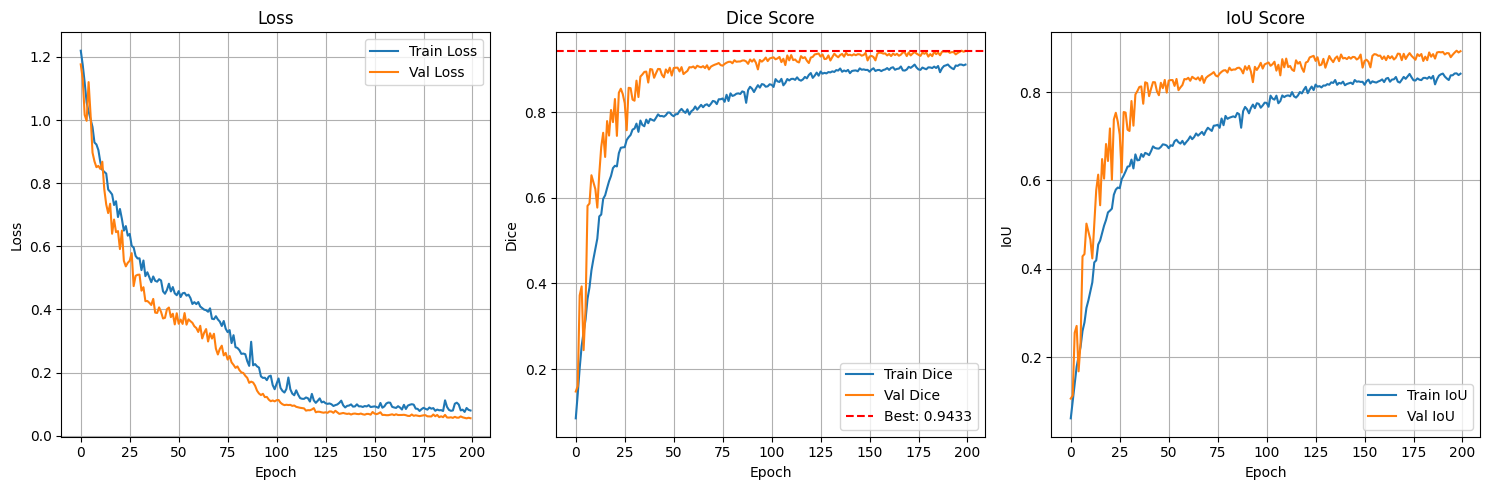

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(history['train_dice'], label='Train Dice')
plt.plot(history['val_dice'], label='Val Dice')
plt.axhline(y=best_dice, color='r', linestyle='--', label=f'Best: {best_dice:.4f}')
plt.xlabel('Epoch')
plt.ylabel('Dice')
plt.title('Dice Score')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(history['train_iou'], label='Train IoU')
plt.plot(history['val_iou'], label='Val IoU')
plt.xlabel('Epoch')
plt.ylabel('IoU')
plt.title('IoU Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()